# 04 — Embedding Analysis (PCA + UMAP / t-SNE)

**Author:** Mostafa · **Project:** Reliable Chest X-Ray AI · **Phase 1, task 1** (`phase1_team_task_distribution.md`) · **Branch:** `feature/data-pipeline`

**Question.** In the space of pretrained image embeddings, do **Normal** and **Abnormal** chest X-rays separate, or do they overlap?
Do the images also cluster by things that are *not* disease, such as view position, scanner settings, sex or age? Those would be
**shortcuts or confounders** that a classifier could exploit.

**Inputs**
- Embeddings already extracted by Tarek: a frozen TorchXRayVision DenseNet121 (`densenet121-res224-chex`) with 1024 dimensions per image, stored as `.npz` chunks in `embeddings_checkpoints/{train,validation,test}`.
- Metadata: `Data/splits/{train,validation,test}_metadata.csv` (balanced 20,000-image subset, patient-wise split).

**Leakage rule.** Every step that learns from the data (scaler, PCA, UMAP) is **fitted on train only** and then applied to
validation and test. Overlap and confounder metrics are computed on train with **5-fold cross-validation grouped by patient**.

**Outputs** (in `OUT_DIR`): 9 figures, 2D coordinates CSV, metric tables (CSV) and `embedding_analysis_config.json` (parameters, seed, package versions).

---

### Results at a glance
| Question | Answer | Key evidence |
|---|---|---|
| Do Normal and Abnormal form separate clusters? | **No, they overlap heavily** | Silhouette 0.03–0.06 · kNN purity 0.57–0.60 (chance = 0.50) · linear AUROC 0.75 on PCA-50 |
| What drives the structure of the embedding space? | **Acquisition (view position and scanner settings)** | AP vs PA AUROC 0.990 · pixel spacing 0.999 · image size 0.964 (same within Normal images only) |
| Are these shortcuts linked to the label? | **Yes** | AP 56.9 % Abnormal vs PA 45.3 % · follow-up >20: 67.8 % vs first visit 33.3 % |
| Is the split consistent? | **Yes** | Validation and test fall on the same regions as train (Figure 09) |

Full findings are in **Section 7**.

## 0. Setup
**Just press Runtime → Run all.** This notebook does everything by itself:
1. It connects your Google Drive (to save the results in your `NIH_ChestXray` folder).
2. It downloads Tarek's embedding chunks (train / validation / test) from his shared link.
3. It downloads the labels (metadata CSV files) from the GitHub branch.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    !pip install -q umap-learn gdown

Mounted at /content/drive


In [2]:
import glob, json, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
import umap

warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
# ---------------- Configuration ----------------
# Tarek's shared folder "embeddings_checkpoints" (it has train / validation / test inside).
# Link: https://drive.google.com/drive/folders/1ZZmQl_Bizu0KJR9TmoYZDjth4Xrnf16K
EMB_FOLDER_ID = "1ZZmQl_Bizu0KJR9TmoYZDjth4Xrnf16K"
EMB_ROOT = os.environ.get("EMB_ROOT", "/content/embeddings_checkpoints")   # local copy inside Colab

# Labels / metadata: read straight from the GitHub branch.
METADATA_ROOT = os.environ.get(
    "METADATA_ROOT",
    "https://raw.githubusercontent.com/tarek0026/Reliable-Chest-X-Ray-AI/feature/data-pipeline/Data/splits",
)

# Results are saved inside your dataset folder on Drive:
# https://drive.google.com/drive/folders/1OwftdnnUp5VHaDXI9i2Qa8K9O_lJdytx  (My Drive/NIH_ChestXray)
OUT_DIR = Path(os.environ.get("OUT_DIR", "/content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis"))

SPLITS = ["train", "validation", "test"]
EXPECTED_ROWS = {"train": 14000, "validation": 3000, "test": 3000}
EMB_DIM = 1024

SEED = 42
PCA_COMPONENTS = 50                     # input to UMAP / t-SNE and to the overlap metrics
UMAP_PARAMS = dict(n_neighbors=30, min_dist=0.1, metric="cosine", random_state=SEED)
UMAP_SENSITIVITY = [15, 30, 50]         # n_neighbors values for the robustness check
TSNE_PARAMS = dict(perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
KNN_K = 15
CV_FOLDS = 5
SILHOUETTE_SAMPLE = 5000

FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
print("Output dir:", OUT_DIR)

Output dir: /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis


In [4]:
# ---------------- Download the embedding chunks (about 1 minute) ----------------
def count_npz(root):
    return {s: len(glob.glob(os.path.join(root, s, "*.npz"))) for s in SPLITS}

if not all(count_npz(EMB_ROOT).values()):
    import gdown
    gdown.download_folder(id=EMB_FOLDER_ID, output=EMB_ROOT, quiet=False)

counts = count_npz(EMB_ROOT)
print("Chunks found:", counts)          # expected: train 7, validation 2, test 2
missing = [s for s, n in counts.items() if n == 0]
assert not missing, (
    f"No chunks for {missing}. Open the Drive link and check these folders have .npz files. "
    "If the download stopped, run this cell again."
)

Retrieving folder contents


Retrieving folder 1KYfDEx_Re8vJQHOyjQQpGYYkbt-vDbGU test
Processing file 1Dyuq76iJjKRS5L9HEIiTdsoKpuQdeklU chunk_000.npz
Processing file 133VBoMszBN8VIJzUbazU10lp6RmoHKaE chunk_001.npz
Retrieving folder 1qswb7oPu6WudP9h6Jo80wxASSFn0b-z8 train
Processing file 17HDzNyrATC3OiYzJfW-DfZ_CPuZHKIuV chunk_000.npz
Processing file 1hXLYXIoWNQKhM0bDUHw3W0L-_SFTZxa9 chunk_001.npz
Processing file 1jU5C7hKQscHsqYRIi3v4qUvRYGmWkO0S chunk_002.npz
Processing file 1usnavhkCU6BsfNZCET1EYdHA8gDxFnBr chunk_003.npz
Processing file 1on4rsNtQsgWtVUQtAOl-iU5jRjHWNQWm chunk_004.npz
Processing file 1dY_q_7vY6qkjojnwmj5925DpeaPOxHuU chunk_005.npz
Processing file 1Cj5TL5q0sdB7RuMHQd-ti6EzdzBb7lBK chunk_006.npz
Retrieving folder 1jSGoQx_v9wTkcQ0IbSmWqwkWXmf_KJ4w validation
Processing file 13ExOj4J4k5uWsvM6S4cA8dx1gw4ExGqH chunk_000.npz
Processing file 1hTVio8L3trchS6iJ-qK8CdErCyFhrNLC chunk_001.npz


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1Dyuq76iJjKRS5L9HEIiTdsoKpuQdeklU
To: /content/embeddings_checkpoints/test/chunk_000.npz
100%|██████████| 6.56M/6.56M [00:00<00:00, 26.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=133VBoMszBN8VIJzUbazU10lp6RmoHKaE
To: /content/embeddings_checkpoints/test/chunk_001.npz
100%|██████████| 3.31M/3.31M [00:00<00:00, 28.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=17HDzNyrATC3OiYzJfW-DfZ_CPuZHKIuV
To: /content/embeddings_checkpoints/train/chunk_000.npz
100%|██████████| 6.52M/6.52M [00:00<00:00, 41.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1hXLYXIoWNQKhM0bDUHw3W0L-_SFTZxa9
To: /content/embeddings_checkpoints/train/chunk_001.npz
100%|██████████| 6.48M/6.48M [00:00<00:00, 34.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1jU5C7hKQscHsqYRIi3v4qUvRYGmWkO0S
To: /content/embeddings_checkpo

Chunks found: {'train': 7, 'validation': 2, 'test': 2}



Download completed


In [5]:
# ---------------- Plot style ----------------
# Fixed categorical order (colorblind-validated palette). Colors follow the category, never its rank.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER_COLOR = "#b5b4ae"
CLASS_COLORS = {"Normal": PALETTE[0], "Abnormal": PALETTE[1]}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7",
    "grid.linewidth": 0.6, "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})

def color_map(categories, fixed=None):
    """Assign palette colors in fixed order; anything past 8 categories goes to grey 'Other'."""
    if fixed:
        return {c: fixed.get(c, OTHER_COLOR) for c in categories}
    return {c: (PALETTE[i] if i < len(PALETTE) else OTHER_COLOR) for i, c in enumerate(categories)}

def scatter_by(ax, xy, labels, title, order=None, fixed=None, s=3, alpha=0.45, max_points=None):
    labels = pd.Series(labels).astype(str).values
    order = order or sorted(pd.unique(labels))
    cmap = color_map(order, fixed)
    idx = np.arange(len(labels))
    if max_points and len(idx) > max_points:
        idx = np.random.default_rng(SEED).choice(idx, max_points, replace=False)
    idx = np.random.default_rng(SEED).permutation(idx)          # random draw order: no class painted on top
    ax.scatter(xy[idx, 0], xy[idx, 1], c=[cmap[l] for l in labels[idx]], s=s, alpha=alpha, linewidths=0)
    handles = [plt.Line2D([], [], marker="o", ls="", color=cmap[c], markersize=6,
                          label=f"{c} (n={int((labels == c).sum()):,})") for c in order]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=min(len(handles), 4), fontsize=8, markerscale=1, columnspacing=1.0, handletextpad=0.3)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    print("saved", FIG_DIR / f"{name}.png")

## 1. Load embeddings and merge with metadata

In [6]:
def load_embeddings(split):
    files = sorted(glob.glob(os.path.join(EMB_ROOT, split, "*.npz")))
    assert files, f"No .npz files found in {os.path.join(EMB_ROOT, split)}"
    names, embs = [], []
    for f in files:
        with np.load(f, allow_pickle=False) as d:
            names.append(d["image_names"]); embs.append(d["embeddings"])
    names = np.concatenate(names).astype(str)
    names = np.array([os.path.basename(n) for n in names])   # keep only the filename
    embs = np.concatenate(embs).astype(np.float32)
    print(f"{split:<10} files={len(files):>3}  images={len(names):>6,}  shape={embs.shape}")
    return names, embs

def load_metadata(split):
    return pd.read_csv(f"{METADATA_ROOT}/{split}_metadata.csv")

frames, emb_blocks = [], []
for split in SPLITS:
    names, embs = load_embeddings(split)
    meta = load_metadata(split)
    order = pd.DataFrame({"image_name": names, "_row": np.arange(len(names))})
    merged = meta.merge(order, on="image_name", how="inner", validate="one_to_one")
    missing = set(meta.image_name) - set(names)
    extra = set(names) - set(meta.image_name)
    print(f"   merged={len(merged):,}  metadata without embedding={len(missing)}  embeddings without metadata={len(extra)}")
    frames.append(merged.drop(columns="_row"))
    emb_blocks.append(embs[merged["_row"].values])

df = pd.concat(frames, ignore_index=True)
X = np.vstack(emb_blocks)
print("\nAll splits:", df.shape, X.shape)

train      files=  7  images=14,000  shape=(14000, 1024)
   merged=14,000  metadata without embedding=0  embeddings without metadata=0
validation files=  2  images= 3,000  shape=(3000, 1024)
   merged=3,000  metadata without embedding=0  embeddings without metadata=0
test       files=  2  images= 3,000  shape=(3000, 1024)
   merged=3,000  metadata without embedding=0  embeddings without metadata=0

All splits: (20000, 14) (20000, 1024)


In [7]:
# ---------------- Integrity checks ----------------
for split in SPLITS:
    n = (df.split == split).sum()
    assert n == EXPECTED_ROWS[split], f"{split}: expected {EXPECTED_ROWS[split]}, got {n}"
assert X.shape[1] == EMB_DIM, X.shape
assert np.isfinite(X).all(), "NaN/inf in embeddings"
assert df.image_name.is_unique, "duplicate image names"
# patient-wise split: no patient in two splits
assert df.groupby("patient_id").split.nunique().max() == 1, "patient appears in more than one split"
dup_vectors = pd.DataFrame(X).duplicated().sum()
print("Row counts OK | dim OK | finite OK | unique names OK | no patient overlap OK")
print("Exactly identical embedding vectors:", dup_vectors, "(non-zero may point to duplicate images; share with Ahmed)")
df.groupby(["split", "binary_label"]).size().unstack()

Row counts OK | dim OK | finite OK | unique names OK | no patient overlap OK
Exactly identical embedding vectors: 0 (non-zero may point to duplicate images; share with Ahmed)


binary_label,Abnormal,Normal
split,,
test,1500,1500
train,7000,7000
validation,1500,1500


### Derived metadata for the confounder analysis
`n_findings` = number of labels on Abnormal images. Image size and pixel spacing act as a proxy for the acquisition device / site.

In [8]:
df["age_group"] = pd.cut(df.patient_age, [0, 18, 40, 60, 80, 200], right=False,
                         labels=["<18", "18-39", "40-59", "60-79", "80+"]).astype(str)
df["n_findings"] = np.where(df.binary_label == "Normal", 0, df.finding_labels.str.count(r"\|") + 1)
df["n_findings_group"] = df.n_findings.clip(upper=3).map({0: "0 (Normal)", 1: "1", 2: "2", 3: "3+"})
df["follow_up_group"] = pd.cut(df.follow_up, [-1, 0, 5, 20, 10_000],
                               labels=["first visit", "1-5", "6-20", ">20"]).astype(str)
df["image_size"] = df.image_width.astype(str) + "x" + df.image_height.astype(str)
top_sizes = df.loc[df.split == "train", "image_size"].value_counts().index[:7]
df["image_size_group"] = df.image_size.where(df.image_size.isin(top_sizes), "Other")
df["pixel_spacing"] = df.pixel_spacing_x.round(3).astype(str)
top_ps = df.loc[df.split == "train", "pixel_spacing"].value_counts().index[:7]
df["pixel_spacing_group"] = df.pixel_spacing.where(df.pixel_spacing.isin(top_ps), "Other")

# Primary finding for Abnormal images (single label, or "Multiple")
df["finding_group"] = np.where(df.binary_label == "Normal", "Normal",
                       np.where(df.n_findings > 1, "Multiple", df.finding_labels))
df["y"] = (df.binary_label == "Abnormal").astype(int)

train = (df.split == "train").values
for col in ["view_position", "patient_sex", "age_group", "image_size_group", "pixel_spacing_group", "follow_up_group"]:
    print(f"\n{col}\n", pd.crosstab(df.loc[train, col], df.loc[train, "binary_label"], margins=True))


view_position
 binary_label   Abnormal  Normal    All
view_position                         
AP                 3231    2443   5674
PA                 3769    4557   8326
All                7000    7000  14000

patient_sex
 binary_label  Abnormal  Normal    All
patient_sex                          
F                 3011    3127   6138
M                 3989    3873   7862
All               7000    7000  14000

age_group
 binary_label  Abnormal  Normal    All
age_group                            
18-39             1764    2112   3876
40-59             3038    3063   6101
60-79             1810    1410   3220
80+                102      55    157
<18                286     360    646
All               7000    7000  14000

image_size_group
 binary_label      Abnormal  Normal    All
image_size_group                         
2021x2021              247     291    538
2048x2500              428     683   1111
2500x2048             2402    2247   4649
2544x3056              148     154    30

## 2. PCA (fit on train only)

PC1 18.8% | PC2 11.7% | PC1+PC2 30.5%
Components for 90% variance: 148 | 95%: 248 | first 50: 79.5%
saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/01_pca_variance.png


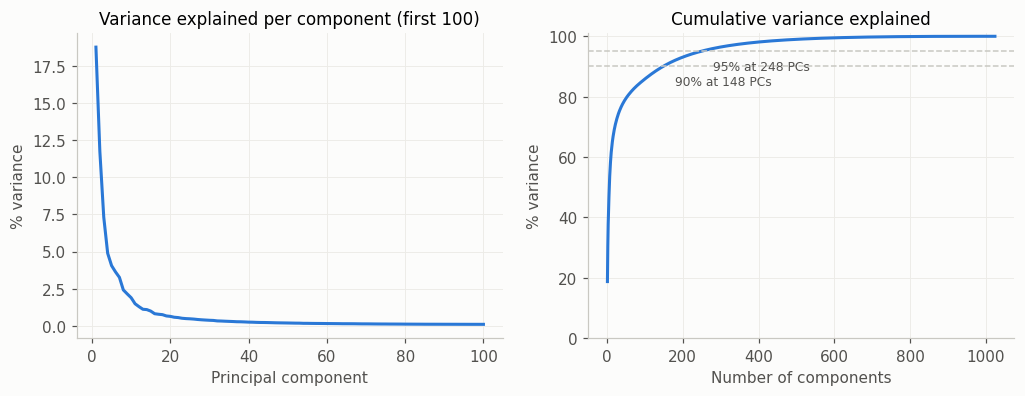

In [9]:
scaler = StandardScaler().fit(X[train])
Xs = scaler.transform(X)

pca_full = PCA(random_state=SEED).fit(Xs[train])
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n90, n95 = int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.95) + 1)
print(f"PC1 {evr[0]:.1%} | PC2 {evr[1]:.1%} | PC1+PC2 {cum[1]:.1%}")
print(f"Components for 90% variance: {n90} | 95%: {n95} | first {PCA_COMPONENTS}: {cum[PCA_COMPONENTS-1]:.1%}")

pca = PCA(n_components=PCA_COMPONENTS, random_state=SEED).fit(Xs[train])
Z = pca.transform(Xs)                          # PCA-50 for all splits (train-fitted)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
k = 100
axes[0].plot(np.arange(1, k + 1), evr[:k] * 100, lw=2, color=PALETTE[0])
axes[0].set(title="Variance explained per component (first 100)", xlabel="Principal component", ylabel="% variance")
axes[1].plot(np.arange(1, len(cum) + 1), cum * 100, lw=2, color=PALETTE[0])
for v, n in [(90, n90), (95, n95)]:
    axes[1].axhline(v, color="#c9c8c2", lw=1, ls="--"); axes[1].annotate(f"{v}% at {n} PCs", (n, v), xytext=(8, -12), textcoords="offset points", fontsize=8, color="#52514e")
axes[1].set(title="Cumulative variance explained", xlabel="Number of components", ylabel="% variance", ylim=(0, 101))
savefig(fig, "01_pca_variance"); plt.show()

**Result.** PC1 explains **18.8 %** and PC2 **11.7 %** of the variance (30.5 % together). The first 50 components keep **79.5 %**.
148 components are needed for 90 % and 248 for 95 %. The information is spread over many directions, so a 2D view can only show part of it.

saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/02_pca_by_class.png


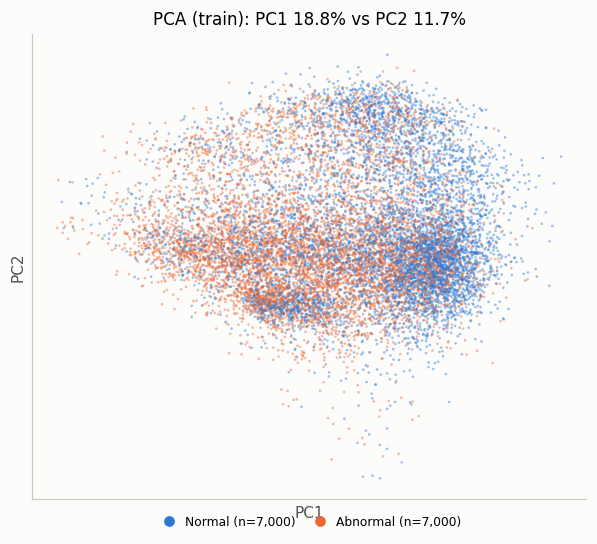

saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/03_pca_marginals.png


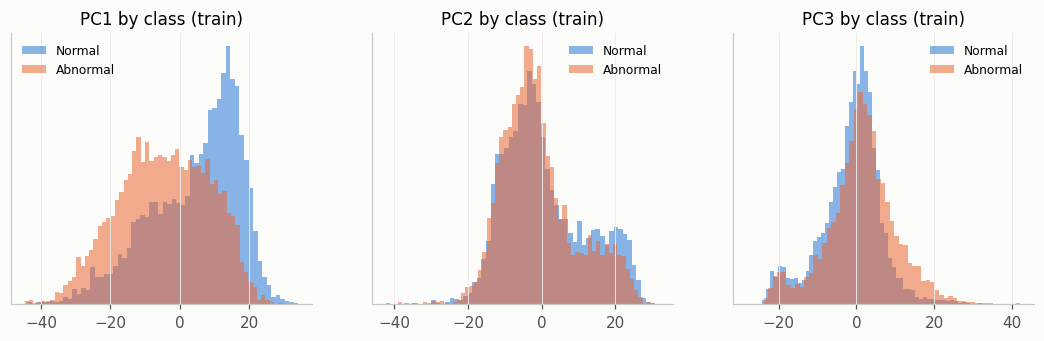

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
scatter_by(ax, Z[train][:, :2], df.loc[train, "binary_label"], f"PCA (train): PC1 {evr[0]:.1%} vs PC2 {evr[1]:.1%}",
           order=["Normal", "Abnormal"], fixed=CLASS_COLORS)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
savefig(fig, "02_pca_by_class"); plt.show()

# Class distributions along the first PCs (overlap seen one axis at a time)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for i, ax in enumerate(axes):
    for cls in ["Normal", "Abnormal"]:
        m = train & (df.binary_label == cls).values
        ax.hist(Z[m, i], bins=60, alpha=0.55, density=True, color=CLASS_COLORS[cls], label=cls)
    ax.set(title=f"PC{i+1} by class (train)", yticks=[]); ax.legend(fontsize=8)
savefig(fig, "03_pca_marginals"); plt.show()

**Result.** On PC1–PC2, Abnormal images lean to the left and Normal images to the right, but the two clouds **overlap strongly** in the centre.
The PC1–PC3 histograms show the same picture: the distributions are shifted, but there is no clear separation.

## 3. UMAP (main 2D view) and t-SNE (cross-check)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/04_umap_by_class_all_splits.png


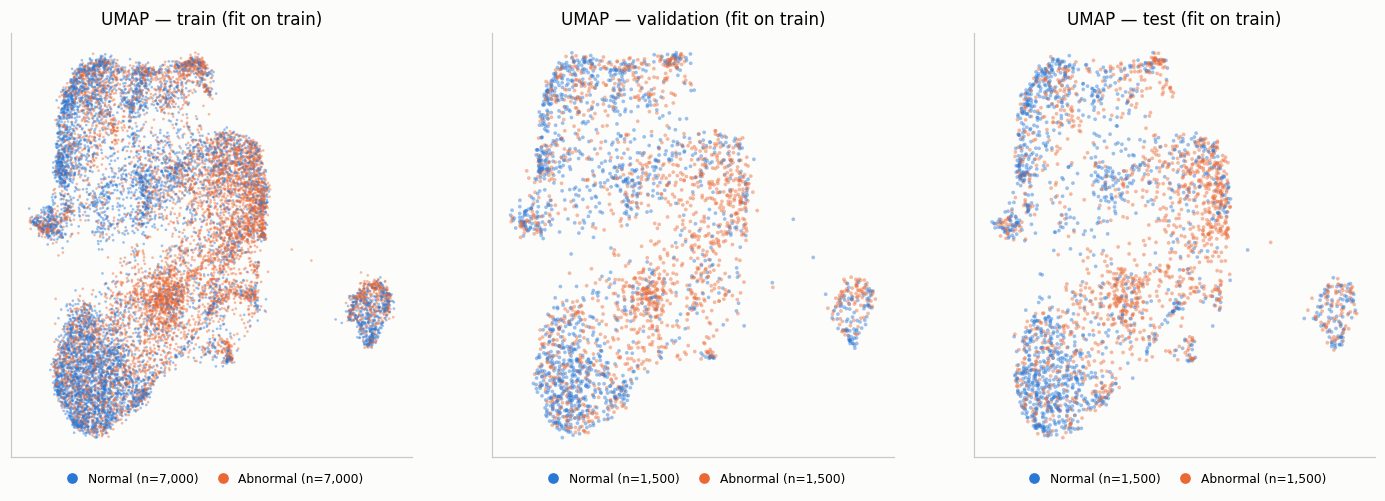

In [11]:
reducer = umap.UMAP(**UMAP_PARAMS).fit(Z[train])
U = reducer.transform(Z)                          # validation/test projected with the train-fitted UMAP

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, split in zip(axes, SPLITS):
    m = (df.split == split).values
    scatter_by(ax, U[m], df.loc[m, "binary_label"], f"UMAP — {split} (fit on train)",
               order=["Normal", "Abnormal"], fixed=CLASS_COLORS, s=3 if split == "train" else 6)
savefig(fig, "04_umap_by_class_all_splits"); plt.show()

**Result.** UMAP shows several large regions and one separate island on the right. Some regions are **mostly Normal** (lower left) and others **mostly Abnormal** (right side),
but no region is pure, and the island contains both classes. Validation and test points land on the same regions as train.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/05_umap_sensitivity.png


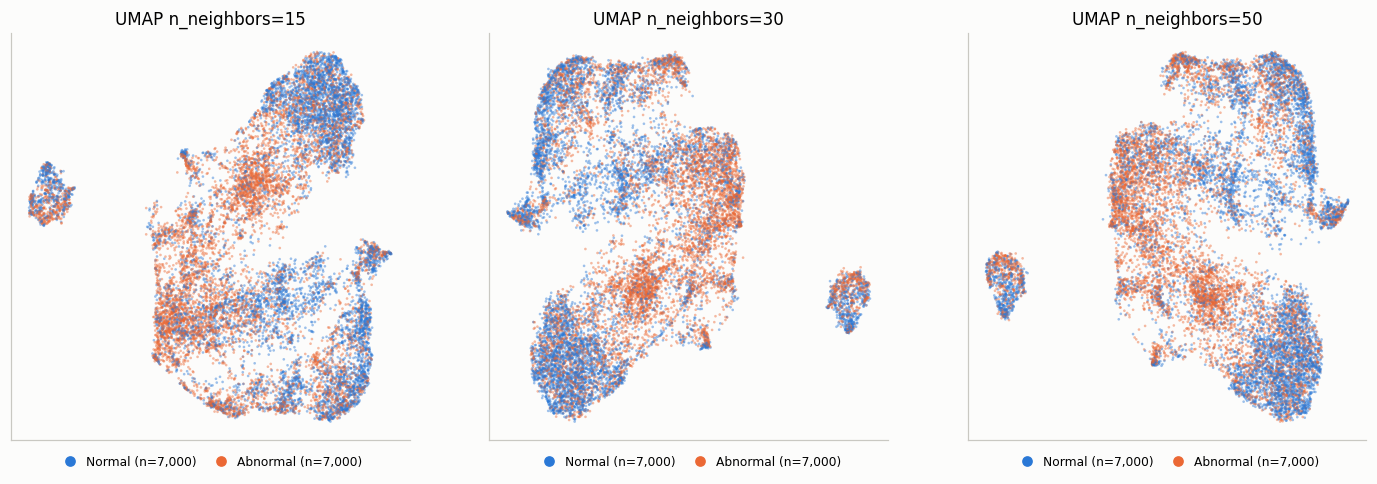

In [12]:
# Robustness: does the picture change with n_neighbors? (train only)
fig, axes = plt.subplots(1, len(UMAP_SENSITIVITY), figsize=(5.3 * len(UMAP_SENSITIVITY), 4.8))
for ax, nn in zip(axes, UMAP_SENSITIVITY):
    emb = umap.UMAP(**{**UMAP_PARAMS, "n_neighbors": nn}).fit_transform(Z[train])
    scatter_by(ax, emb, df.loc[train, "binary_label"], f"UMAP n_neighbors={nn}", order=["Normal", "Abnormal"], fixed=CLASS_COLORS)
savefig(fig, "05_umap_sensitivity"); plt.show()

**Result.** The overall shape and the class pattern are the same for n_neighbors = 15, 30 and 50, so the map is not an artefact of one parameter choice.

saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/06_tsne_by_class.png


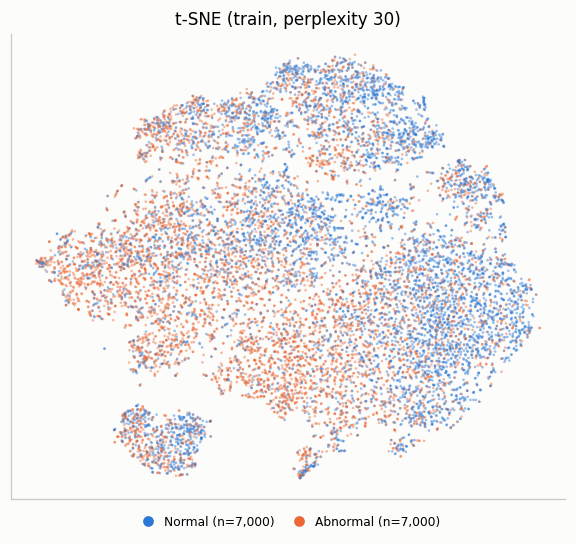

In [13]:
T = TSNE(**TSNE_PARAMS).fit_transform(Z[train])   # t-SNE cannot transform new points: train only
fig, ax = plt.subplots(figsize=(6.5, 5.5))
scatter_by(ax, T, df.loc[train, "binary_label"], "t-SNE (train, perplexity 30)", order=["Normal", "Abnormal"], fixed=CLASS_COLORS)
savefig(fig, "06_tsne_by_class"); plt.show()

**Result.** t-SNE gives the same conclusion as UMAP: there are class-enriched areas, but heavy overlap and no separate Normal or Abnormal cluster.

## 4. Measuring class overlap
- **Silhouette score** by class: near 0 = classes overlap, near 1 = well separated.
- **kNN class purity**: share of each image's 15 nearest neighbours (PCA-50 space) with the same label. 0.5 = chance for a balanced set.
- **Linear separability**: 5-fold patient-grouped CV AUROC of logistic regression on PC1–2, PCA-50 and all 1024 dims (train only).
  This is a diagnostic, not the official baseline.

In [14]:
rng = np.random.default_rng(SEED)
y_tr = df.loc[train, "y"].values
g_tr = df.loc[train, "patient_id"].values
sil_idx = rng.choice(train.sum(), min(SILHOUETTE_SAMPLE, train.sum()), replace=False)

def knn_purity(F, labels, k=KNN_K):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(F)
    _, ind = nn.kneighbors(F)
    neigh = labels[ind[:, 1:]]                    # drop self
    return (neigh == labels[:, None]).mean(axis=1)

def cv_auc(F, y, groups, stratify=True):
    cv = StratifiedGroupKFold(CV_FOLDS, shuffle=True, random_state=SEED) if stratify else GroupKFold(CV_FOLDS)
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    s = cross_val_score(clf, F, y, groups=groups, cv=cv, scoring="roc_auc")
    return s.mean(), s.std()

spaces = {"PC1-2": Z[train][:, :2], f"PCA-{PCA_COMPONENTS}": Z[train], "UMAP-2D": U[train], "Raw 1024": X[train]}
rows = []
for name, F in spaces.items():
    auc_m, auc_s = cv_auc(F, y_tr, g_tr)
    row = {"space": name, "cv_auroc_mean": auc_m, "cv_auroc_std": auc_s}
    if name != "Raw 1024":                        # geometry metrics only on the reduced spaces
        pur = knn_purity(F, y_tr)
        row.update(silhouette=silhouette_score(F[sil_idx], y_tr[sil_idx]), knn_purity_all=pur.mean(),
                   knn_purity_normal=pur[y_tr == 0].mean(), knn_purity_abnormal=pur[y_tr == 1].mean())
    rows.append(row)
overlap = pd.DataFrame(rows).set_index("space").round(3)
overlap

,cv_auroc_mean,cv_auroc_std,silhouette,knn_purity_all,knn_purity_normal,knn_purity_abnormal
space,,,,,,
PC1-2,0.697,0.010,0.057,0.570,0.570,0.570
PCA-50,0.750,0.008,0.028,0.596,0.612,0.580
UMAP-2D,0.646,0.014,0.036,0.577,0.579,0.575
Raw 1024,0.723,0.005,NaN,NaN,NaN,NaN


**Result.**
- **Silhouette** is 0.028–0.057 in every space, which means no class clusters.
- **kNN purity** is 0.57–0.60. Each image's neighbours are only slightly more often of its own class than chance (0.50).
- **Linear AUROC** is 0.697 on 2 PCs and 0.750 on 50 PCs. All 1024 raw dimensions are not better (0.723).
- There is a real but weak class signal, and a simple model on frozen embeddings reaches about **0.75 AUROC**.

In [15]:
# Which Abnormal findings sit closest to the Normal cloud? (kNN purity of Abnormal images, PCA-50)
pur50 = knn_purity(Z[train], y_tr)
ab = df.loc[train].assign(purity=pur50)
ab = ab[ab.y == 1]
by_finding = ab.groupby("finding_group").purity.agg(["count", "mean"]).sort_values("mean").round(3)
by_finding.rename(columns={"mean": "share_of_abnormal_neighbours"})

,count,share_of_abnormal_neighbours
finding_group,,
Hernia,43,0.397
Nodule,308,0.445
Infiltration,640,0.459
Fibrosis,134,0.466
Pleural_Thickening,132,0.483
Atelectasis,340,0.506
Cardiomegaly,171,0.519
Mass,247,0.531
Pneumonia,58,0.531


**Result.** Abnormal images with **Hernia (0.397), Nodule (0.445), Infiltration (0.459), Fibrosis (0.466) and Pleural thickening (0.483)** have mostly *Normal* neighbours,
so these findings look "normal" in this space. **Edema, Consolidation, Effusion (0.615–0.625)** and multi-finding images (0.629) are the most distinct.

## 5. Shortcuts and confounders
Same UMAP map, recoloured by non-disease metadata. If a variable forms its **own clusters**, the embedding encodes it strongly.
If that variable is also **unevenly distributed between Normal and Abnormal**, a model can use it as a shortcut.

saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/07_umap_by_metadata.png


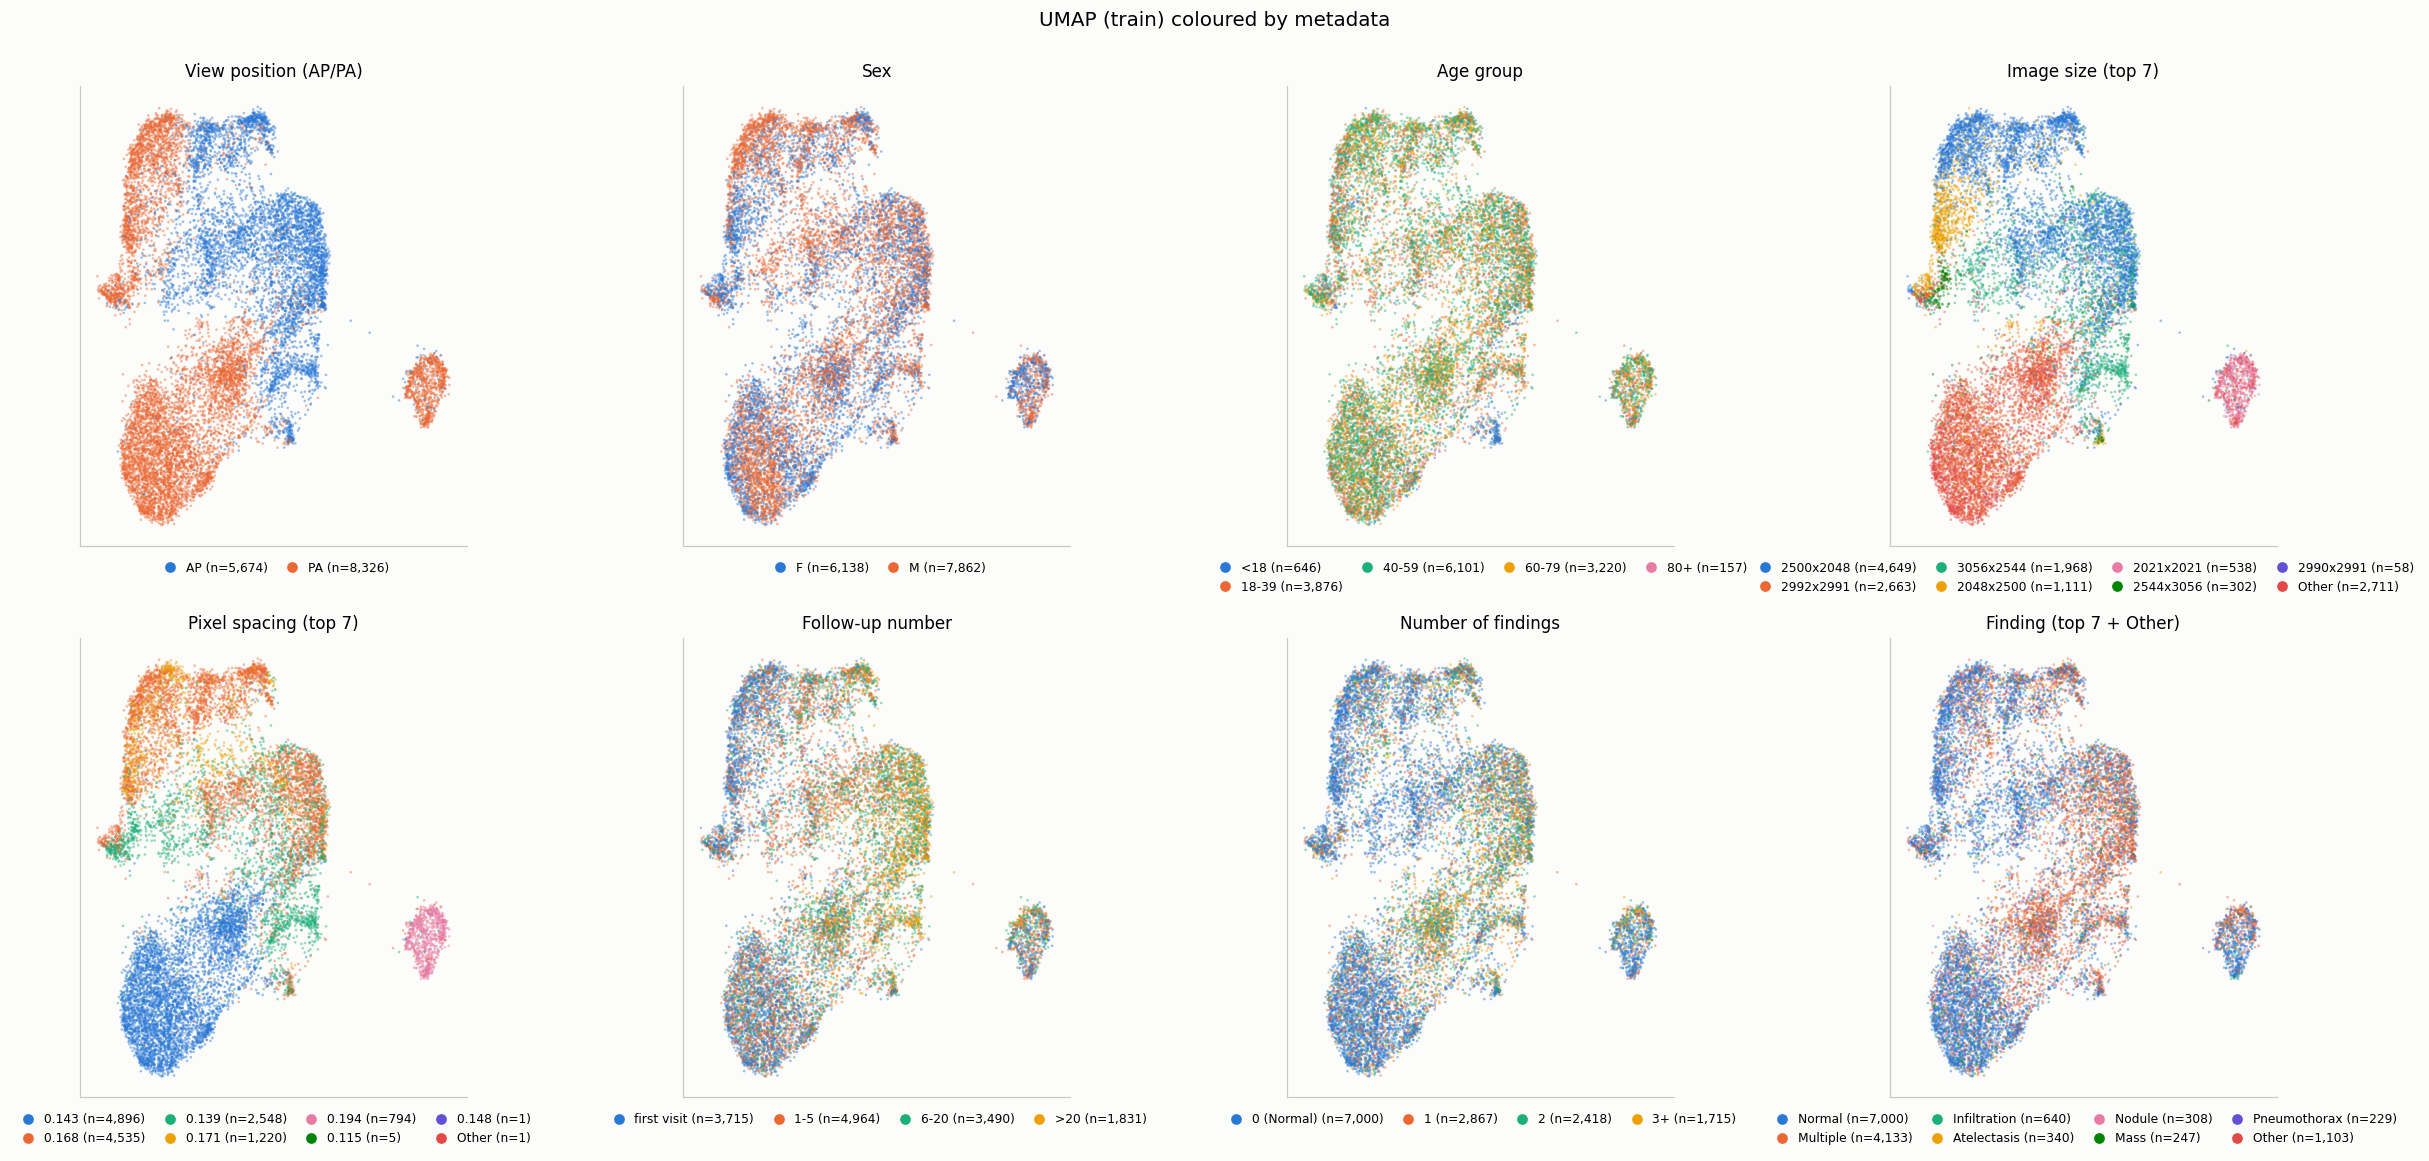

In [16]:
CONF_COLS = [
    ("view_position", "View position (AP/PA)"),
    ("patient_sex", "Sex"),
    ("age_group", "Age group"),
    ("image_size_group", "Image size (top 7)"),
    ("pixel_spacing_group", "Pixel spacing (top 7)"),
    ("follow_up_group", "Follow-up number"),
    ("n_findings_group", "Number of findings"),
    ("finding_group", "Finding (top 7 + Other)"),
]
age_order = ["<18", "18-39", "40-59", "60-79", "80+"]
fig, axes = plt.subplots(2, 4, figsize=(22, 10.5))
for ax, (col, title) in zip(axes.ravel(), CONF_COLS):
    lab = df.loc[train, col].astype(str)
    if col == "finding_group":
        top = lab[lab != "Normal"].value_counts().index[:6].tolist()
        lab = lab.where(lab.isin(top + ["Normal"]), "Other"); order = ["Normal"] + top + ["Other"]
    elif col == "age_group":
        order = [a for a in age_order if a in set(lab)]
    elif col == "follow_up_group":
        order = [c for c in ["first visit", "1-5", "6-20", ">20"] if c in set(lab)]
    elif col in ("image_size_group", "pixel_spacing_group"):
        order = [c for c in lab.value_counts().index if c != "Other"] + (["Other"] if "Other" in set(lab) else [])
    else:
        order = sorted(lab.unique())
    scatter_by(ax, U[train], lab, title, order=order)
plt.suptitle("UMAP (train) coloured by metadata", y=1.0, fontsize=13)
plt.tight_layout(); savefig(fig, "07_umap_by_metadata"); plt.show()

**Result.** The metadata explains the map's structure much better than disease does:
- **View position:** AP and PA occupy clearly different regions.
- **Pixel spacing and image size:** each region matches a specific scanner setting. The separate island on the right is the group with image size 2021×2021 and pixel spacing 0.194, which is probably a different device.
- **Sex** shows a visible pattern within regions. **Age** and **follow-up number** show weaker gradients.
- The **Normal-rich** lower-left region is mainly PA images with pixel spacing 0.143. The **Abnormal-rich** right side is mainly AP images.

saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/08_umap_class_within_view.png


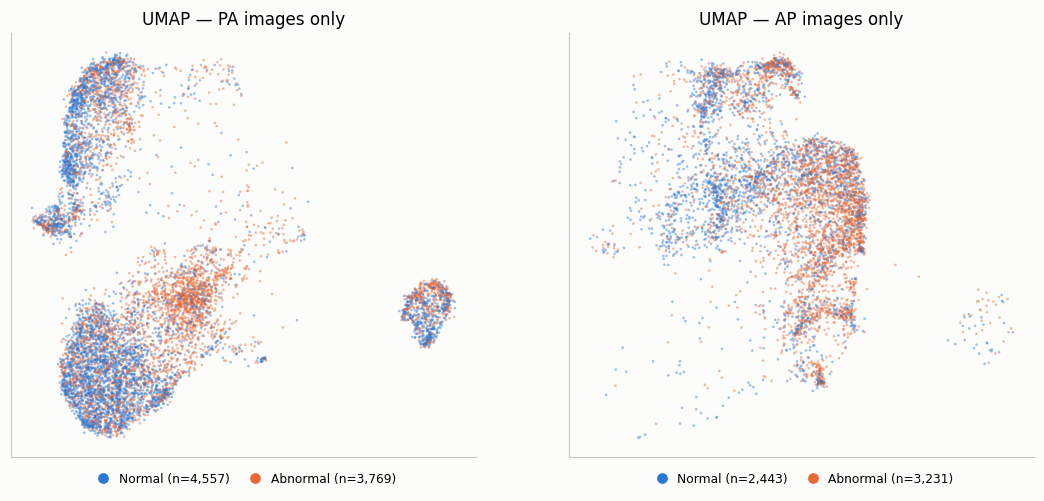

saved /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis/figures/09_umap_by_split.png


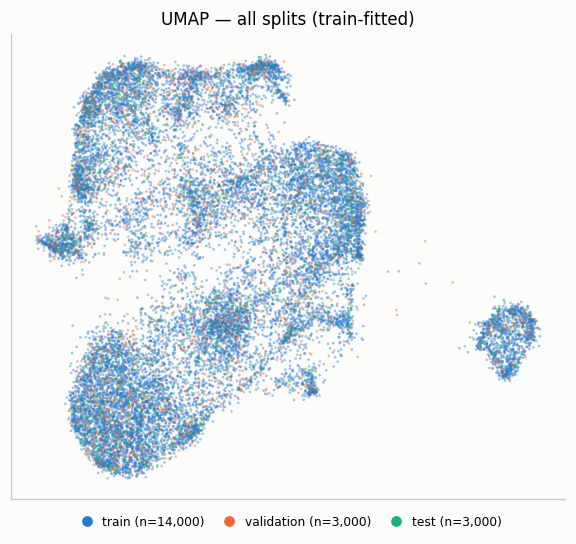

In [17]:
# Class within each view: is the Normal/Abnormal pattern the same for AP and PA?
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, v in zip(axes, ["PA", "AP"]):
    m = train & (df.view_position == v).values
    scatter_by(ax, U[m], df.loc[m, "binary_label"], f"UMAP — {v} images only", order=["Normal", "Abnormal"], fixed=CLASS_COLORS)
savefig(fig, "08_umap_class_within_view"); plt.show()

# Split check: do validation/test fall on the same map as train (distribution shift)?
fig, ax = plt.subplots(figsize=(6.5, 5.5))
scatter_by(ax, U, df.split, "UMAP — all splits (train-fitted)", order=SPLITS, s=3)
savefig(fig, "09_umap_by_split"); plt.show()

**Result.** Within PA images and within AP images there are still Normal-rich and Abnormal-rich areas, so some disease signal exists beyond view position.
AP images are mostly Abnormal (3,231 of 5,674). In Figure 09, train, validation and test are spread evenly over the same regions, so there is **no visible distribution shift** between splits.

### Quantifying the confounders
1. **Association with the label** (train): share Abnormal in each subgroup.
2. **How strongly the embedding encodes each variable**: patient-grouped CV AUROC of a logistic regression that predicts the variable from PCA-50.
   Computed **within Normal images only** too, so the result cannot be explained by disease.
3. **Label AUROC within each subgroup**: if Normal/Abnormal is much easier to separate in one view than the other, evaluation must be stratified.

In [18]:
tr = df.loc[train].reset_index(drop=True)
Ztr = Z[train]

assoc = []
for col, _ in CONF_COLS[:6]:
    t = tr.groupby(col).y.agg(n="size", pct_abnormal="mean")
    t["variable"] = col
    assoc.append(t.reset_index().rename(columns={col: "group"}))
assoc = pd.concat(assoc)[["variable", "group", "n", "pct_abnormal"]]
assoc["pct_abnormal"] = (assoc.pct_abnormal * 100).round(1)
assoc

,variable,group,n,pct_abnormal
0,view_position,AP,5674,56.9
1,view_position,PA,8326,45.3
0,patient_sex,F,6138,49.1
1,patient_sex,M,7862,50.7
0,age_group,18-39,3876,45.5
1,age_group,40-59,6101,49.8
2,age_group,60-79,3220,56.2
3,age_group,80+,157,65.0
4,age_group,<18,646,44.3
0,image_size_group,2021x2021,538,45.9


**Result.** The label is not independent of acquisition. Abnormal makes up **56.9 % of AP vs 45.3 % of PA**, **57.3 % at pixel spacing 0.139 vs 37.9 % at 0.171**,
**59.3 % for size 3056×2544 vs 38.5 % for 2048×2500**, and **33.3 % at first visit vs 67.8 % after more than 20 follow-ups**. Sex is balanced (49.1 % vs 50.7 %).

In [19]:
def encode_target(col):
    s = tr[col].astype(str)
    if col == "view_position": return (s == "AP").astype(int).values, "AP vs PA"
    if col == "patient_sex":   return (s == "M").astype(int).values, "M vs F"
    if col in ("image_size_group", "pixel_spacing_group"):
        top = s.value_counts().index[0]; return (s == top).astype(int).values, f"{top} vs rest"
    return None, None

enc_rows = []
for col in ["view_position", "patient_sex", "image_size_group", "pixel_spacing_group"]:
    yv, desc = encode_target(col)
    for subset_name, m in [("all train", np.ones(len(tr), bool)), ("Normal only", (tr.y == 0).values)]:
        if len(np.unique(yv[m])) < 2: continue
        auc_m, auc_s = cv_auc(Ztr[m], yv[m], tr.patient_id.values[m])
        enc_rows.append({"variable": col, "target": desc, "subset": subset_name, "cv_auroc": round(auc_m, 3), "std": round(auc_s, 3)})

# Age: regression R^2 (patient-grouped CV)
for subset_name, m in [("all train", np.ones(len(tr), bool)), ("Normal only", (tr.y == 0).values)]:
    r2 = cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=10.0)), Ztr[m], tr.patient_age.values[m],
                         groups=tr.patient_id.values[m], cv=GroupKFold(CV_FOLDS), scoring="r2")
    enc_rows.append({"variable": "patient_age", "target": "age (R^2)", "subset": subset_name, "cv_auroc": round(r2.mean(), 3), "std": round(r2.std(), 3)})

encodability = pd.DataFrame(enc_rows)
encodability   # for age the score column is R^2, not AUROC

,variable,target,subset,cv_auroc,std
0,view_position,AP vs PA,all train,0.990,0.002
1,view_position,AP vs PA,Normal only,0.989,0.001
2,patient_sex,M vs F,all train,0.850,0.010
3,patient_sex,M vs F,Normal only,0.876,0.011
4,image_size_group,2500x2048 vs rest,all train,0.964,0.003
5,image_size_group,2500x2048 vs rest,Normal only,0.971,0.005
6,pixel_spacing_group,0.143 vs rest,all train,0.999,0.000
7,pixel_spacing_group,0.143 vs rest,Normal only,0.999,0.000
8,patient_age,age (R^2),all train,0.311,0.026
9,patient_age,age (R^2),Normal only,0.327,0.024


**Result.** The embeddings predict **view position (AUROC 0.990)**, **pixel spacing (0.999)** and **image size (0.964)** almost perfectly. They also predict **sex (0.850)** and partly age (**R² 0.311**).
The values are the same **within Normal images only** (0.989 / 0.999 / 0.971 / 0.876 / 0.327), so they are not explained by disease.
All of these are far higher than Normal vs Abnormal (0.750).

In [20]:
sub_rows = []
for col in ["view_position", "patient_sex", "age_group"]:
    for grp, part in tr.groupby(col):
        m = (tr[col] == grp).values
        if part.y.nunique() < 2 or min(part.y.value_counts()) < 50: continue
        auc_m, auc_s = cv_auc(Ztr[m], tr.y.values[m], tr.patient_id.values[m])
        sub_rows.append({"variable": col, "group": grp, "n": int(m.sum()), "pct_abnormal": round(part.y.mean() * 100, 1),
                         "label_cv_auroc": round(auc_m, 3), "std": round(auc_s, 3)})
subgroup_auc = pd.DataFrame(sub_rows)
subgroup_auc

,variable,group,n,pct_abnormal,label_cv_auroc,std
0,view_position,AP,5674,56.9,0.718,0.019
1,view_position,PA,8326,45.3,0.755,0.005
2,patient_sex,F,6138,49.1,0.741,0.014
3,patient_sex,M,7862,50.7,0.758,0.012
4,age_group,18-39,3876,45.5,0.783,0.024
5,age_group,40-59,6101,49.8,0.737,0.010
6,age_group,60-79,3220,56.2,0.695,0.014
7,age_group,80+,157,65.0,0.508,0.098
8,age_group,<18,646,44.3,0.798,0.048


**Result.** Normal vs Abnormal is harder for **AP (0.718) than PA (0.755)**, and harder for older patients:
18–39 years reach 0.783, while 60–79 years reach 0.695. The 80+ group (n = 157) is too small to judge (0.508 ± 0.098).

## 6. Save outputs

In [21]:
coords = df[["image_name", "patient_id", "split", "binary_label", "finding_labels", "view_position",
             "patient_sex", "patient_age", "image_width", "image_height", "pixel_spacing_x"]].copy()
coords[["pc1", "pc2"]] = Z[:, :2]
coords[["umap1", "umap2"]] = U
coords.loc[train, "tsne1"] = T[:, 0]; coords.loc[train, "tsne2"] = T[:, 1]
coords.to_csv(OUT_DIR / "embedding_2d_coordinates.csv", index=False)

overlap.to_csv(OUT_DIR / "class_overlap_metrics.csv")
by_finding.to_csv(OUT_DIR / "abnormal_knn_purity_by_finding.csv")
assoc.to_csv(OUT_DIR / "confounder_label_association.csv", index=False)
encodability.to_csv(OUT_DIR / "confounder_encodability.csv", index=False)
subgroup_auc.to_csv(OUT_DIR / "label_auroc_by_subgroup.csv", index=False)

config = {
    "embeddings": {"source": EMB_ROOT, "model": "TorchXRayVision DenseNet121 densenet121-res224-chex (frozen)", "dim": EMB_DIM},
    "metadata": METADATA_ROOT, "rows": {s: int((df.split == s).sum()) for s in SPLITS},
    "seed": SEED, "fit_on": "train only (scaler, PCA, UMAP); validation/test transformed",
    "scaler": "StandardScaler", "pca_components": PCA_COMPONENTS,
    "pca_variance": {"pc1": float(evr[0]), "pc2": float(evr[1]), f"first_{PCA_COMPONENTS}": float(cum[PCA_COMPONENTS - 1]),
                     "n_components_90pct": n90, "n_components_95pct": n95},
    "umap": UMAP_PARAMS, "umap_sensitivity_n_neighbors": UMAP_SENSITIVITY, "tsne": TSNE_PARAMS,
    "knn_k": KNN_K, "cv": f"{CV_FOLDS}-fold patient-grouped (StratifiedGroupKFold)", "silhouette_sample": SILHOUETTE_SAMPLE,
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "scikit-learn": sklearn.__version__, "umap-learn": umap.__version__},
}
with open(OUT_DIR / "embedding_analysis_config.json", "w") as f:
    json.dump(config, f, indent=2, default=str)
print("Saved to", OUT_DIR); print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to /content/drive/MyDrive/NIH_ChestXray/Embedding_Analysis
['abnormal_knn_purity_by_finding.csv', 'class_overlap_metrics.csv', 'confounder_encodability.csv', 'confounder_label_association.csv', 'embedding_2d_coordinates.csv', 'embedding_analysis_config.json', 'figures', 'label_auroc_by_subgroup.csv']


## 7. Findings and conclusions

All numbers below come from the outputs above (train split, 5-fold patient-grouped cross-validation, seed 42).

### Finding 1: Normal and Abnormal overlap heavily, with only a weak class signal
- **Observation:** The two classes do not form separate clusters in PCA, UMAP or t-SNE (Figures 02, 04, 06). Some regions are class-enriched, but none is pure.
- **Evidence:** Silhouette is 0.028–0.057. kNN purity is 0.57–0.60, against a chance level of 0.50. Linear AUROC is 0.697 on PC1–2, 0.750 on PCA-50 and 0.723 on the raw 1024 dimensions.
- **Implication:** Frozen pretrained features give only a moderate signal for this binary task. Label noise from report mining probably adds to the overlap.
- **Recommendation:** Expect the embedding baselines (Logistic Regression, SVM) to reach about **0.75 AUROC**, and use that as the reference that fine-tuned CNNs must beat. Report AUROC and AUPRC, not accuracy.

### Finding 2: The embedding space is organised by acquisition, not by disease (shortcut risk)
- **Observation:** AP/PA and scanner settings (pixel spacing, image size) form the main regions of the map. One device group (2021×2021, spacing 0.194) forms its own island (Figure 07).
- **Evidence:** AP vs PA AUROC is 0.990, pixel spacing 0.999 and image size 0.964, compared with 0.750 for disease. The values stay the same within Normal images only (0.989 / 0.999 / 0.971). These variables are also linked to the label: Abnormal is 56.9 % for AP vs 45.3 % for PA, 57.3 % vs 37.9 % across pixel-spacing groups, and 59.3 % vs 38.5 % across image sizes.
- **Implication:** A model can raise its score by learning "AP view / this scanner means Abnormal" instead of lung findings. Overall metrics may then overestimate real medical ability and may not transfer to hospitals with a different AP/PA or scanner mix.
- **Recommendation:** In Phase 2, report all metrics separately for **AP and PA** and for the main **pixel-spacing groups**. Add a **metadata-only baseline** (view, pixel spacing, image size, age, sex) to measure how much a shortcut alone can achieve. Consider a view-balanced evaluation subset.

### Finding 3: Abnormal images come more often from older and frequently imaged patients
- **Observation:** The share of Abnormal images rises with the follow-up number and with age. Sex and age are also encoded in the embeddings.
- **Evidence:** Abnormal is 33.3 % at first visit, 47.8 % at 1–5 follow-ups, 61.6 % at 6–20 and 67.8 % above 20. By age it is 45.5 % (18–39), 49.8 % (40–59), 56.2 % (60–79) and 65.0 % (80+). Sex is predicted with an AUROC of 0.850 and age with an R² of 0.311, while the label is balanced by sex (49.1 % vs 50.7 %).
- **Implication:** Patients with many visits contribute many similar images, which would cause leakage without a patient-wise split. Age is a second possible shortcut.
- **Recommendation:** Keep the patient-wise split (verified here: no patient appears in two splits). Do not use `follow_up` as a model input. Include age-group and follow-up-group results in the Phase 2 subgroup analysis.

### Finding 4: Separation is weaker for AP images and older patients
- **Observation:** The class signal is not equally strong in every subgroup.
- **Evidence:** AUROC is 0.755 for PA vs 0.718 for AP, and 0.783 for ages 18–39 vs 0.737 (40–59) and 0.695 (60–79). The 80+ group (n = 157) is unreliable (0.508 ± 0.098).
- **Implication:** A good overall score can hide weaker performance for AP and elderly patients, who are often the more critical cases.
- **Recommendation:** Report subgroup metrics with confidence intervals in Phase 2, and mark the 80+ group as having insufficient data.

### Finding 5: Subtle findings sit inside the Normal region
- **Observation:** Abnormal images with small or diffuse findings mostly have Normal neighbours.
- **Evidence:** The share of Abnormal neighbours is 0.397 for Hernia, 0.445 for Nodule, 0.459 for Infiltration, 0.466 for Fibrosis and 0.483 for Pleural thickening. It is 0.615–0.629 for Edema, Consolidation, Effusion and multi-finding images.
- **Implication:** False negatives are likely to concentrate in these findings. They are also natural candidates for uncertainty-based referral.
- **Recommendation:** In Phase 2, measure sensitivity for each finding and check whether referral catches these cases.

### Additional checks
- **Data integrity:** 14,000 / 3,000 / 3,000 images, all matched to metadata, no missing values, no identical embedding vectors, and no patient in more than one split.
- **Split consistency:** validation and test cover the same regions as train (Figure 09), so there is no visible distribution shift.
- **Robustness:** UMAP gives the same picture for n_neighbors = 15, 30 and 50 (Figure 05), and t-SNE agrees (Figure 06).

### Limitations
- One frozen model only (DenseNet121 trained on CheXpert). Other encoders may organise the data differently.
- 2D maps distort distances, so the conclusions rest on the numeric metrics computed in the 50-dimensional space.
- "Encoded" does not prove that a classifier *uses* the shortcut. That needs the Phase 2 subgroup and metadata-only tests.

### Summary for the final report
On frozen DenseNet121 embeddings, Normal and Abnormal **overlap heavily** (silhouette about 0.03, linear AUROC 0.75). The embedding space is organised mainly by
**acquisition**: view position (AUROC 0.99), pixel spacing (0.999) and image size (0.96). These variables are linked to the label (AP 56.9 % vs PA 45.3 % Abnormal), which makes them
**shortcut risks**. The Abnormal share also rises with follow-up count (33 % → 68 %) and age, which confirms the need for the patient-wise split and subgroup evaluation. Separation is weaker
for AP images (0.72) and patients aged 60–79 (0.70), and subtle findings (Nodule, Infiltration, Fibrosis, Hernia) lie inside the Normal region.
**Phase 2 decisions:** stratify metrics by AP/PA, scanner group and age; add a metadata-only shortcut baseline; check per-finding sensitivity; use about 0.75 AUROC as the embedding-baseline reference.